## Dataset Overview: Airline Passenger Satisfaction
**MCC Data Science Track — Week 4: Classification (Session)**

This dataset contains **25,976 records** and **25 columns** (22 predictive features, 2 identifier/index columns, and 1 binary target), sourced from the 25,976-row benchmark split of the Airline Passenger Satisfaction survey. The goal is to predict whether a passenger is **`satisfied`** or **`neutral or dissatisfied`** based on passenger demographics, flight details, in-flight service ratings, and delay times.

### Features Description
| Feature | Data Type | Role | Description |
| :--- | :--- | :--- | :--- |
| **`Unnamed: 0`** | Numerical | Identifier *(Drop)* | Row index column exported from the original file |
| **`id`** | Numerical | Identifier *(Drop)* | Unique passenger identifier |
| **`Gender`** | Categorical | Feature | Gender of the passenger (`Female`, `Male`) |
| **`Customer Type`** | Categorical | Feature | Loyalty status of the passenger (`Loyal Customer`, `disloyal Customer`) |
| **`Age`** | Numerical | Feature | Age of the passenger (years) |
| **`Type of Travel`** | Categorical | Feature | Purpose of the flight (`Personal Travel`, `Business travel`) |
| **`Class`** | Categorical (Ordinal) | Feature | Travel cabin class (`Eco`, `Eco Plus`, `Business`) |
| **`Flight Distance`** | Numerical | Feature | Total flight distance of the journey (miles) |
| **`Inflight wifi service`** | Numerical (Ordinal) | Feature | Satisfaction rating for in-flight Wi-Fi (`0`: Not Applicable, `1–5`) |
| **`Departure/Arrival time convenient`** | Numerical (Ordinal) | Feature | Satisfaction rating for departure/arrival time convenience (`0–5`) |
| **`Ease of Online booking`** | Numerical (Ordinal) | Feature | Satisfaction rating for online booking process (`0–5`) |
| **`Gate location`** | Numerical (Ordinal) | Feature | Satisfaction rating for gate location (`0–5`) |
| **`Food and drink`** | Numerical (Ordinal) | Feature | Satisfaction rating for food and drink quality (`0–5`) |
| **`Online boarding`** | Numerical (Ordinal) | Feature | Satisfaction rating for online boarding experience (`0–5`) |
| **`Seat comfort`** | Numerical (Ordinal) | Feature | Satisfaction rating for seat comfort (`0–5`) |
| **`Inflight entertainment`** | Numerical (Ordinal) | Feature | Satisfaction rating for in-flight entertainment (`0–5`) |
| **`On-board service`** | Numerical (Ordinal) | Feature | Satisfaction rating for on-board service (`0–5`) |
| **`Leg room service`** | Numerical (Ordinal) | Feature | Satisfaction rating for leg room space (`0–5`) |
| **`Baggage handling`** | Numerical (Ordinal) | Feature | Satisfaction rating for baggage handling (`1–5`) |
| **`Checkin service`** | Numerical (Ordinal) | Feature | Satisfaction rating for check-in service (`0–5`) |
| **`Inflight service`** | Numerical (Ordinal) | Feature | Satisfaction rating for overall in-flight service (`0–5`) |
| **`Cleanliness`** | Numerical (Ordinal) | Feature | Satisfaction rating for aircraft cleanliness (`0–5`) |
| **`Departure Delay in Minutes`** | Numerical | Feature | Delay duration at departure (minutes) |
| **`Arrival Delay in Minutes`** | Numerical | Feature | Delay duration upon arrival (minutes) |
| **`satisfaction`** | Categorical | **Target ($y$)** | Overall passenger satisfaction level (`satisfied` vs. `neutral or dissatisfied`) |

**Source:** [Kaggle — Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction)

In [168]:
from pathlib import Path

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

pd.set_option("display.max_columns", None)

CURRENT_DIR = Path.cwd()
DATA_PATH = CURRENT_DIR / "airline_passenger_satisfaction.csv"

assert DATA_PATH.exists(), f"Dataset not found at: {DATA_PATH}"

# 1. Data Understanding and Cleaning

In [130]:
df = pd.read_csv(DATA_PATH)

df.sample(5)

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
19260,19260,103009,Male,Loyal Customer,45,Business travel,Business,546,4,4,4,4,3,4,4,2,2,2,2,3,2,4,7,0.0,satisfied
21558,21558,3839,Male,Loyal Customer,21,Personal Travel,Eco,710,5,4,5,2,1,5,1,1,4,5,2,2,1,1,0,0.0,satisfied
19105,19105,42364,Male,Loyal Customer,52,Personal Travel,Eco,329,5,2,5,4,5,5,5,5,4,2,4,3,3,5,0,0.0,satisfied
10790,10790,35289,Female,Loyal Customer,26,Business travel,Business,2169,1,1,1,1,4,4,4,4,1,4,4,3,3,4,0,0.0,satisfied
3698,3698,99908,Male,Loyal Customer,41,Business travel,Business,1428,4,4,4,4,3,4,5,4,4,4,4,5,4,5,0,12.0,satisfied


In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  str    
 3   Customer Type                      25976 non-null  str    
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  str    
 6   Class                              25976 non-null  str    
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int64  
 12  F

In [132]:
df = df.drop(columns=['Unnamed: 0', 'id'])

In [133]:
df.isnull().sum()

Gender                                0
Customer Type                         0
Age                                   0
Type of Travel                        0
Class                                 0
Flight Distance                       0
Inflight wifi service                 0
Departure/Arrival time convenient     0
Ease of Online booking                0
Gate location                         0
Food and drink                        0
Online boarding                       0
Seat comfort                          0
Inflight entertainment                0
On-board service                      0
Leg room service                      0
Baggage handling                      0
Checkin service                       0
Inflight service                      0
Cleanliness                           0
Departure Delay in Minutes            0
Arrival Delay in Minutes             83
satisfaction                          0
dtype: int64

In [134]:
df = df.dropna()

In [135]:
df.duplicated().sum()

np.int64(0)

In [136]:
# Numerical Static Description 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,25893.0,39.621983,15.134224,7.0,27.0,40.0,51.0,85.0
Flight Distance,25893.0,1193.753254,998.626779,31.0,414.0,849.0,1744.0,4983.0
Inflight wifi service,25893.0,2.723709,1.334711,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,25893.0,3.046422,1.532971,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,25893.0,2.755996,1.412552,0.0,2.0,3.0,4.0,5.0
Gate location,25893.0,2.976442,1.281661,1.0,2.0,3.0,4.0,5.0
Food and drink,25893.0,3.214923,1.331895,0.0,2.0,3.0,4.0,5.0
Online boarding,25893.0,3.261615,1.355505,0.0,2.0,4.0,4.0,5.0
Seat comfort,25893.0,3.448886,1.320254,1.0,2.0,4.0,5.0,5.0
Inflight entertainment,25893.0,3.356969,1.338643,0.0,2.0,4.0,4.0,5.0


In [137]:
filt1 = (df['Departure Delay in Minutes'] <= 12) & (df['Departure Delay in Minutes'] > 0)

len(df[filt1])

4865

In [138]:
filt2 = (df['Arrival Delay in Minutes'] <= 13) & (df['Arrival Delay in Minutes'] > 0)

len(df[filt2])

4982

In [139]:
# Categorical Static Description
df.select_dtypes('str').describe().T

,count,unique,top,freq
Gender,25893,2,Female,13127
Customer Type,25893,2,Loyal Customer,21111
Type of Travel,25893,2,Business travel,17980
Class,25893,3,Business,12457
satisfaction,25893,2,neutral or dissatisfied,14528


In [140]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')

# 2. Visualization and Feature Eng

In [141]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')

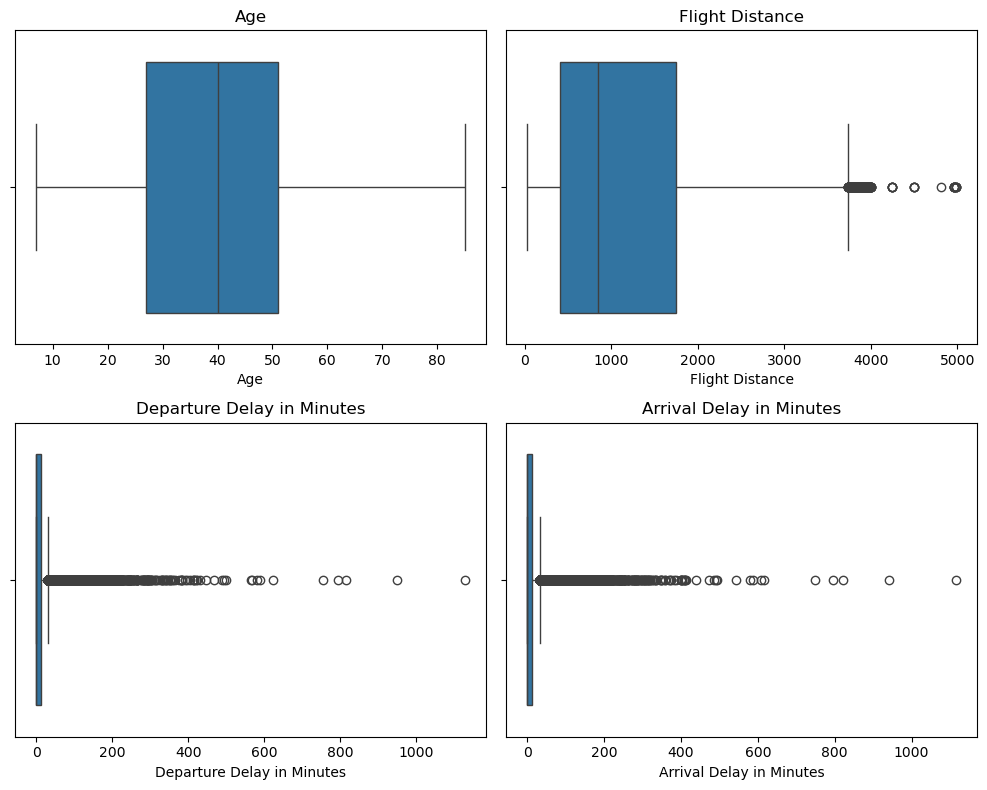

In [142]:
# Visualize the box plot for outliers
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

plt.figure(figsize=(10, 8))

for index, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, index)
    sns.boxplot(data=df, x=col)
    plt.title(col)

plt.tight_layout()
plt.show()

In [143]:
outliers_summary = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[col][(df[col] < lower_bound) | (df[col] > upper_bound)]

    outliers_summary.append({
        'Feature': col,
        'Outliers Count': len(outliers),
        'Outliers Percentage': (len(outliers) / df[col].notna().sum()) * 100
    })

outliers_summary = pd.DataFrame(outliers_summary)

display(outliers_summary)

,Feature,Outliers Count,Outliers Percentage
0,Age,0,0.000000
1,Flight Distance,580,2.239988
2,Departure Delay in Minutes,3542,13.679373
3,Arrival Delay in Minutes,3538,13.663925


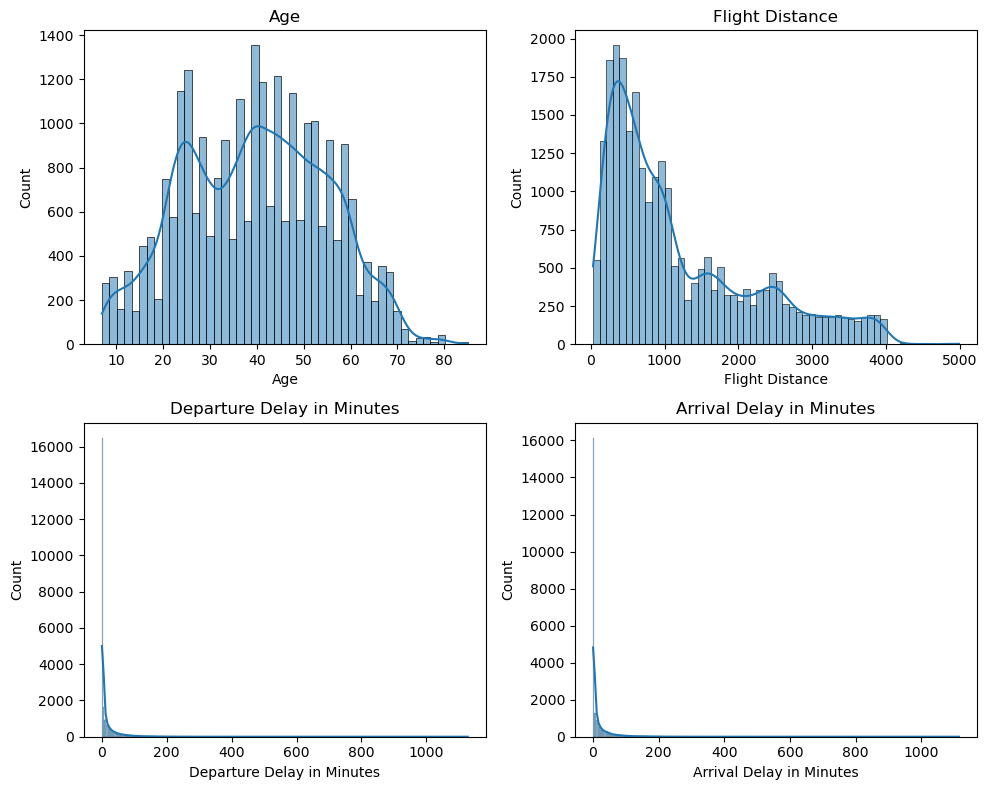

In [144]:
# Visualize the distribution of num data
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

plt.figure(figsize=(10, 8))

for index, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, index)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

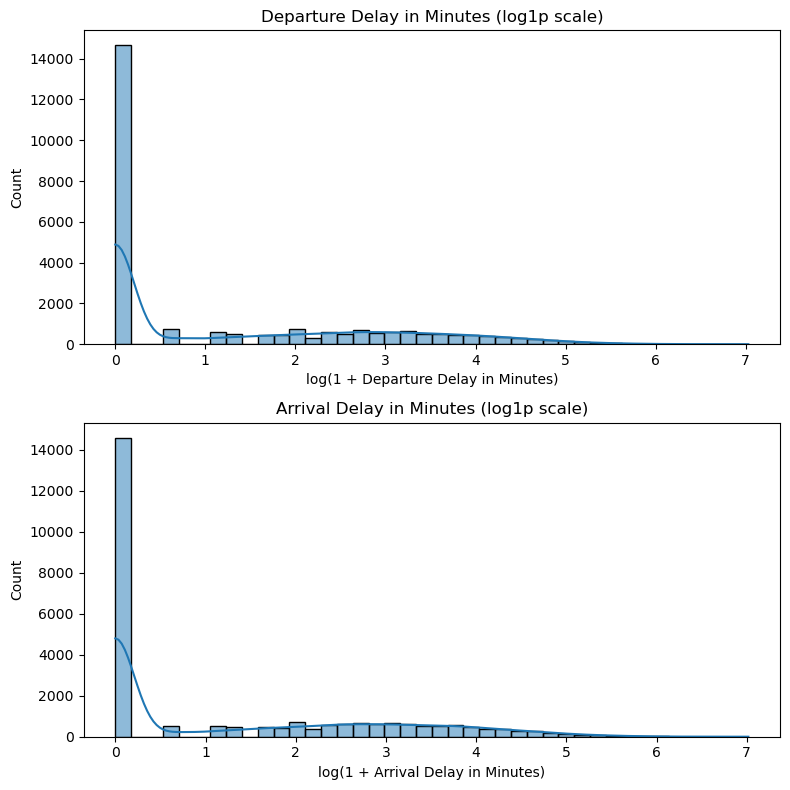

In [145]:
delay_cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']

fig, axes = plt.subplots(2, 1, figsize=(8, 8))

# Transform delay cols with log1p to see the distribution clearly
for idx, col in enumerate(delay_cols):
    sns.histplot(np.log1p(df[col]), bins=40, kde=True, ax=axes[idx])
    axes[idx].set_title(f"{col} (log1p scale)")
    axes[idx].set_xlabel(f"log(1 + {col})")

plt.tight_layout()
plt.show()

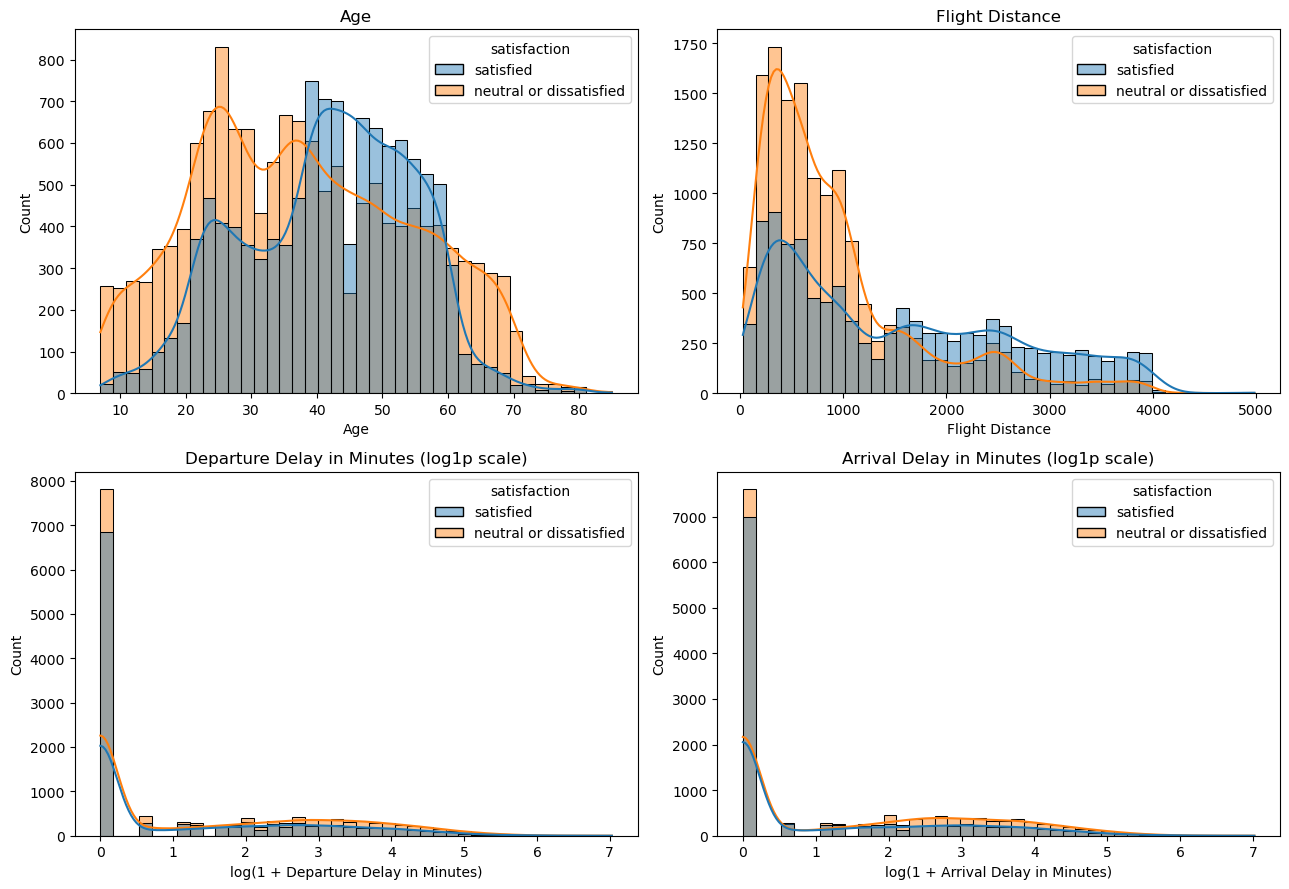

In [146]:
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
delay_cols = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    x_data = np.log1p(df[col]) if col in delay_cols else df[col]
    sns.histplot(data=df, x=x_data, hue='satisfaction', bins=40, kde=True, alpha=0.45, ax=axes[idx])
    
    if col in delay_cols:
        axes[idx].set_title(f"{col} (log1p scale)")
        axes[idx].set_xlabel(f"log(1 + {col})")
    else:
        axes[idx].set_title(col)

plt.tight_layout()
plt.show()

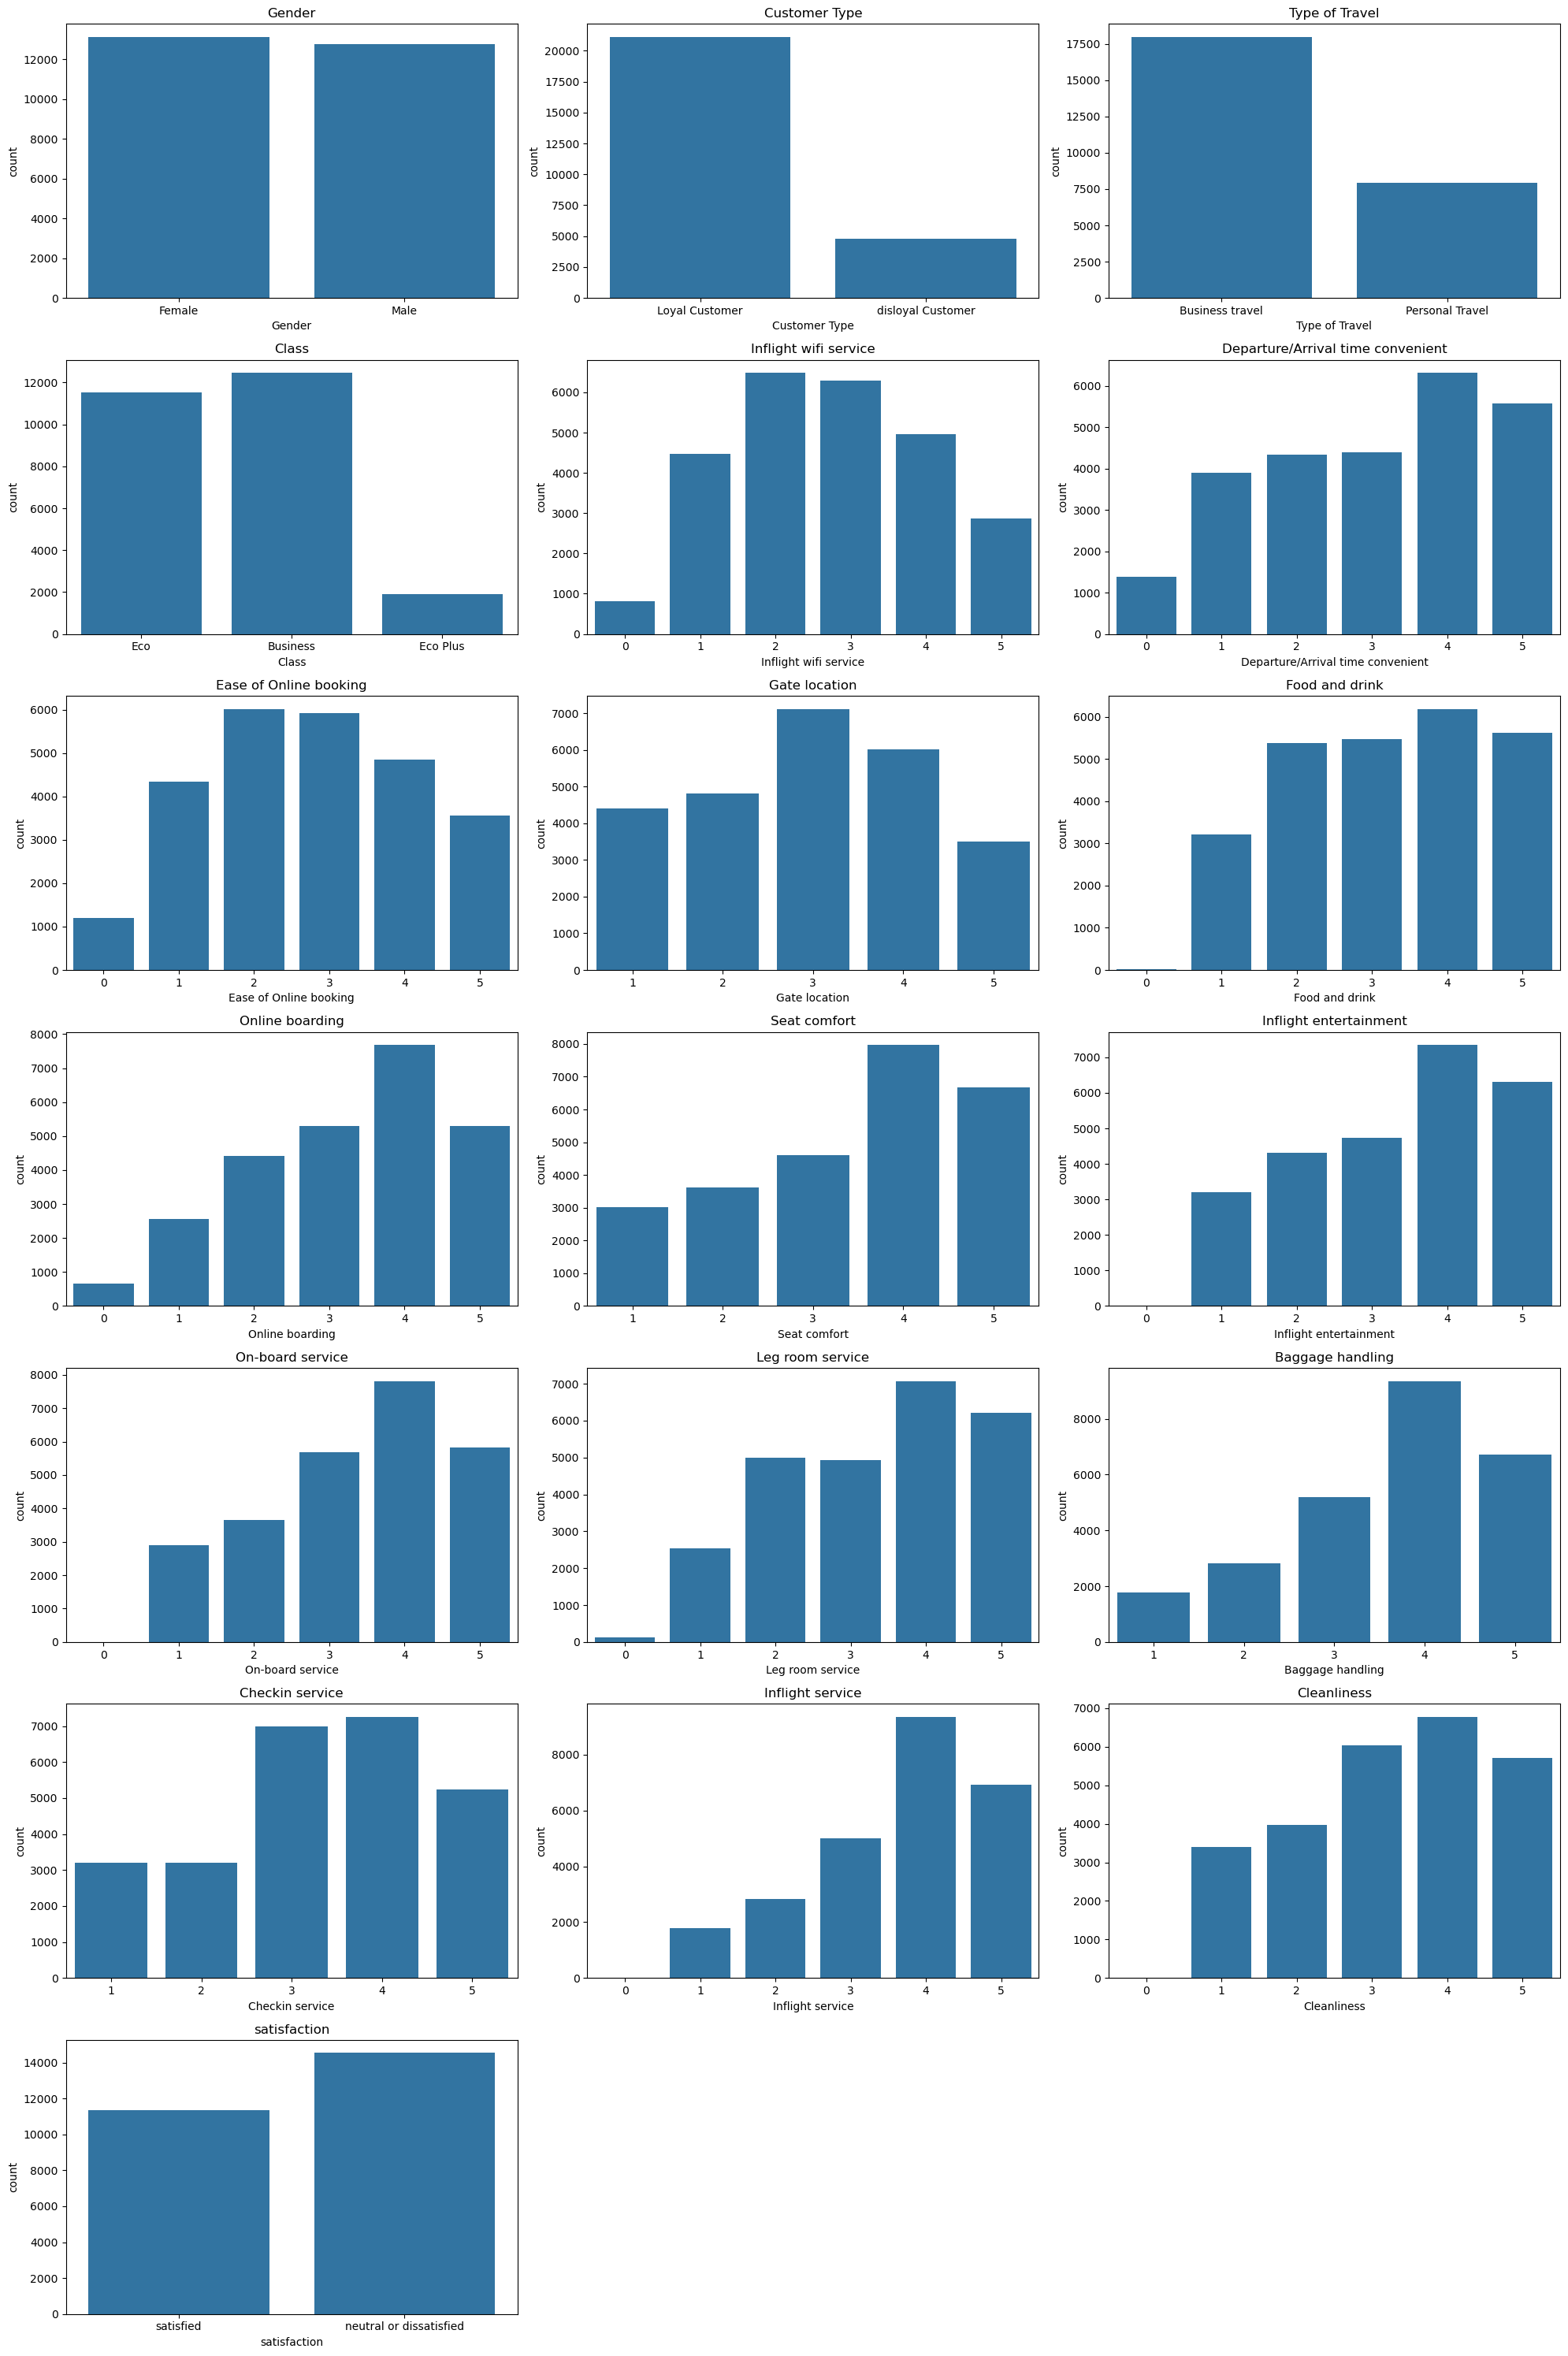

In [148]:
# Cat Columns Distribution
cat_cols = ['Gender', 'Customer Type', 'Type of Travel',
       'Class', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness',
       'satisfaction']

plt.figure(figsize=(20, 30))

for index, col in enumerate(cat_cols, 1):
    plt.subplot(7, 3, index)

    counts = df[col].value_counts(dropna=False)

    sns.countplot(data=df, x=col)

    plt.title(col)

plt.tight_layout()
plt.show()

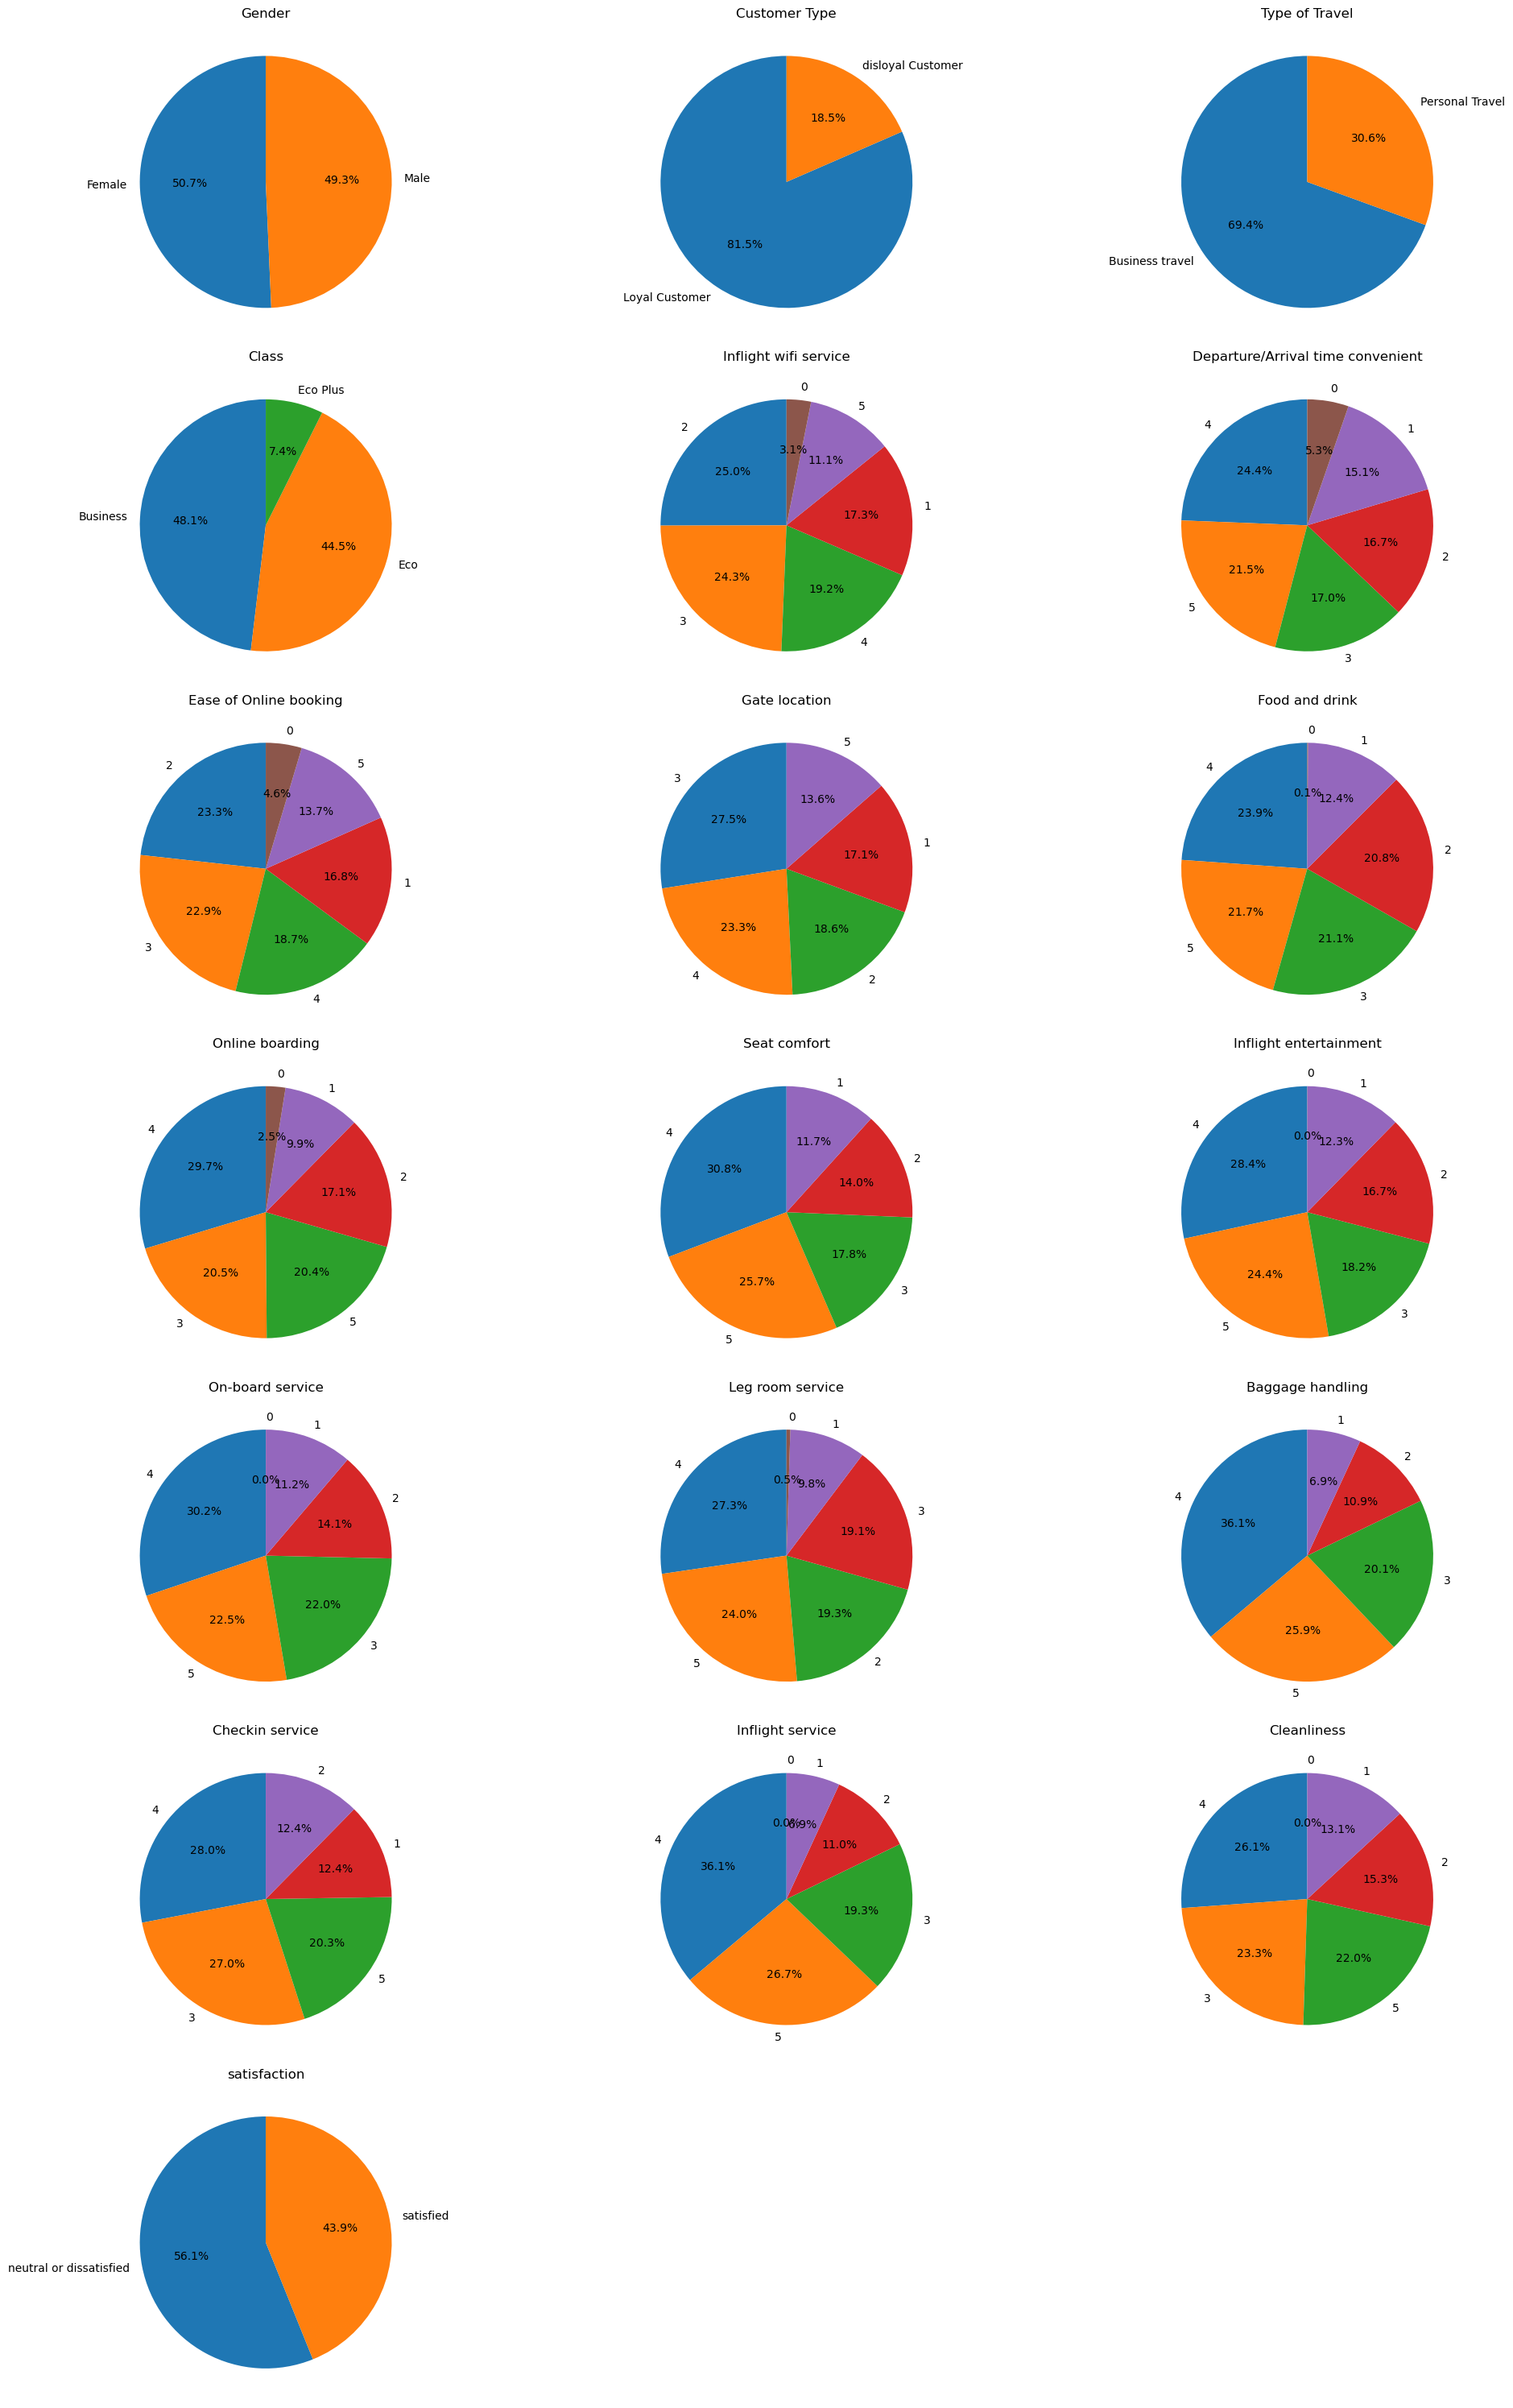

In [147]:
# Cat Columns Distribution
cat_cols = ['Gender', 'Customer Type', 'Type of Travel',
       'Class', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness',
       'satisfaction']

plt.figure(figsize=(20, 30))

for index, col in enumerate(cat_cols, 1):
    plt.subplot(7, 3, index)

    counts = df[col].value_counts(dropna=False)

    plt.pie(
        counts,
        labels=counts.index,
        autopct='%.1f%%',
        startangle=90
    )

    plt.title(col)

plt.tight_layout()
plt.show()

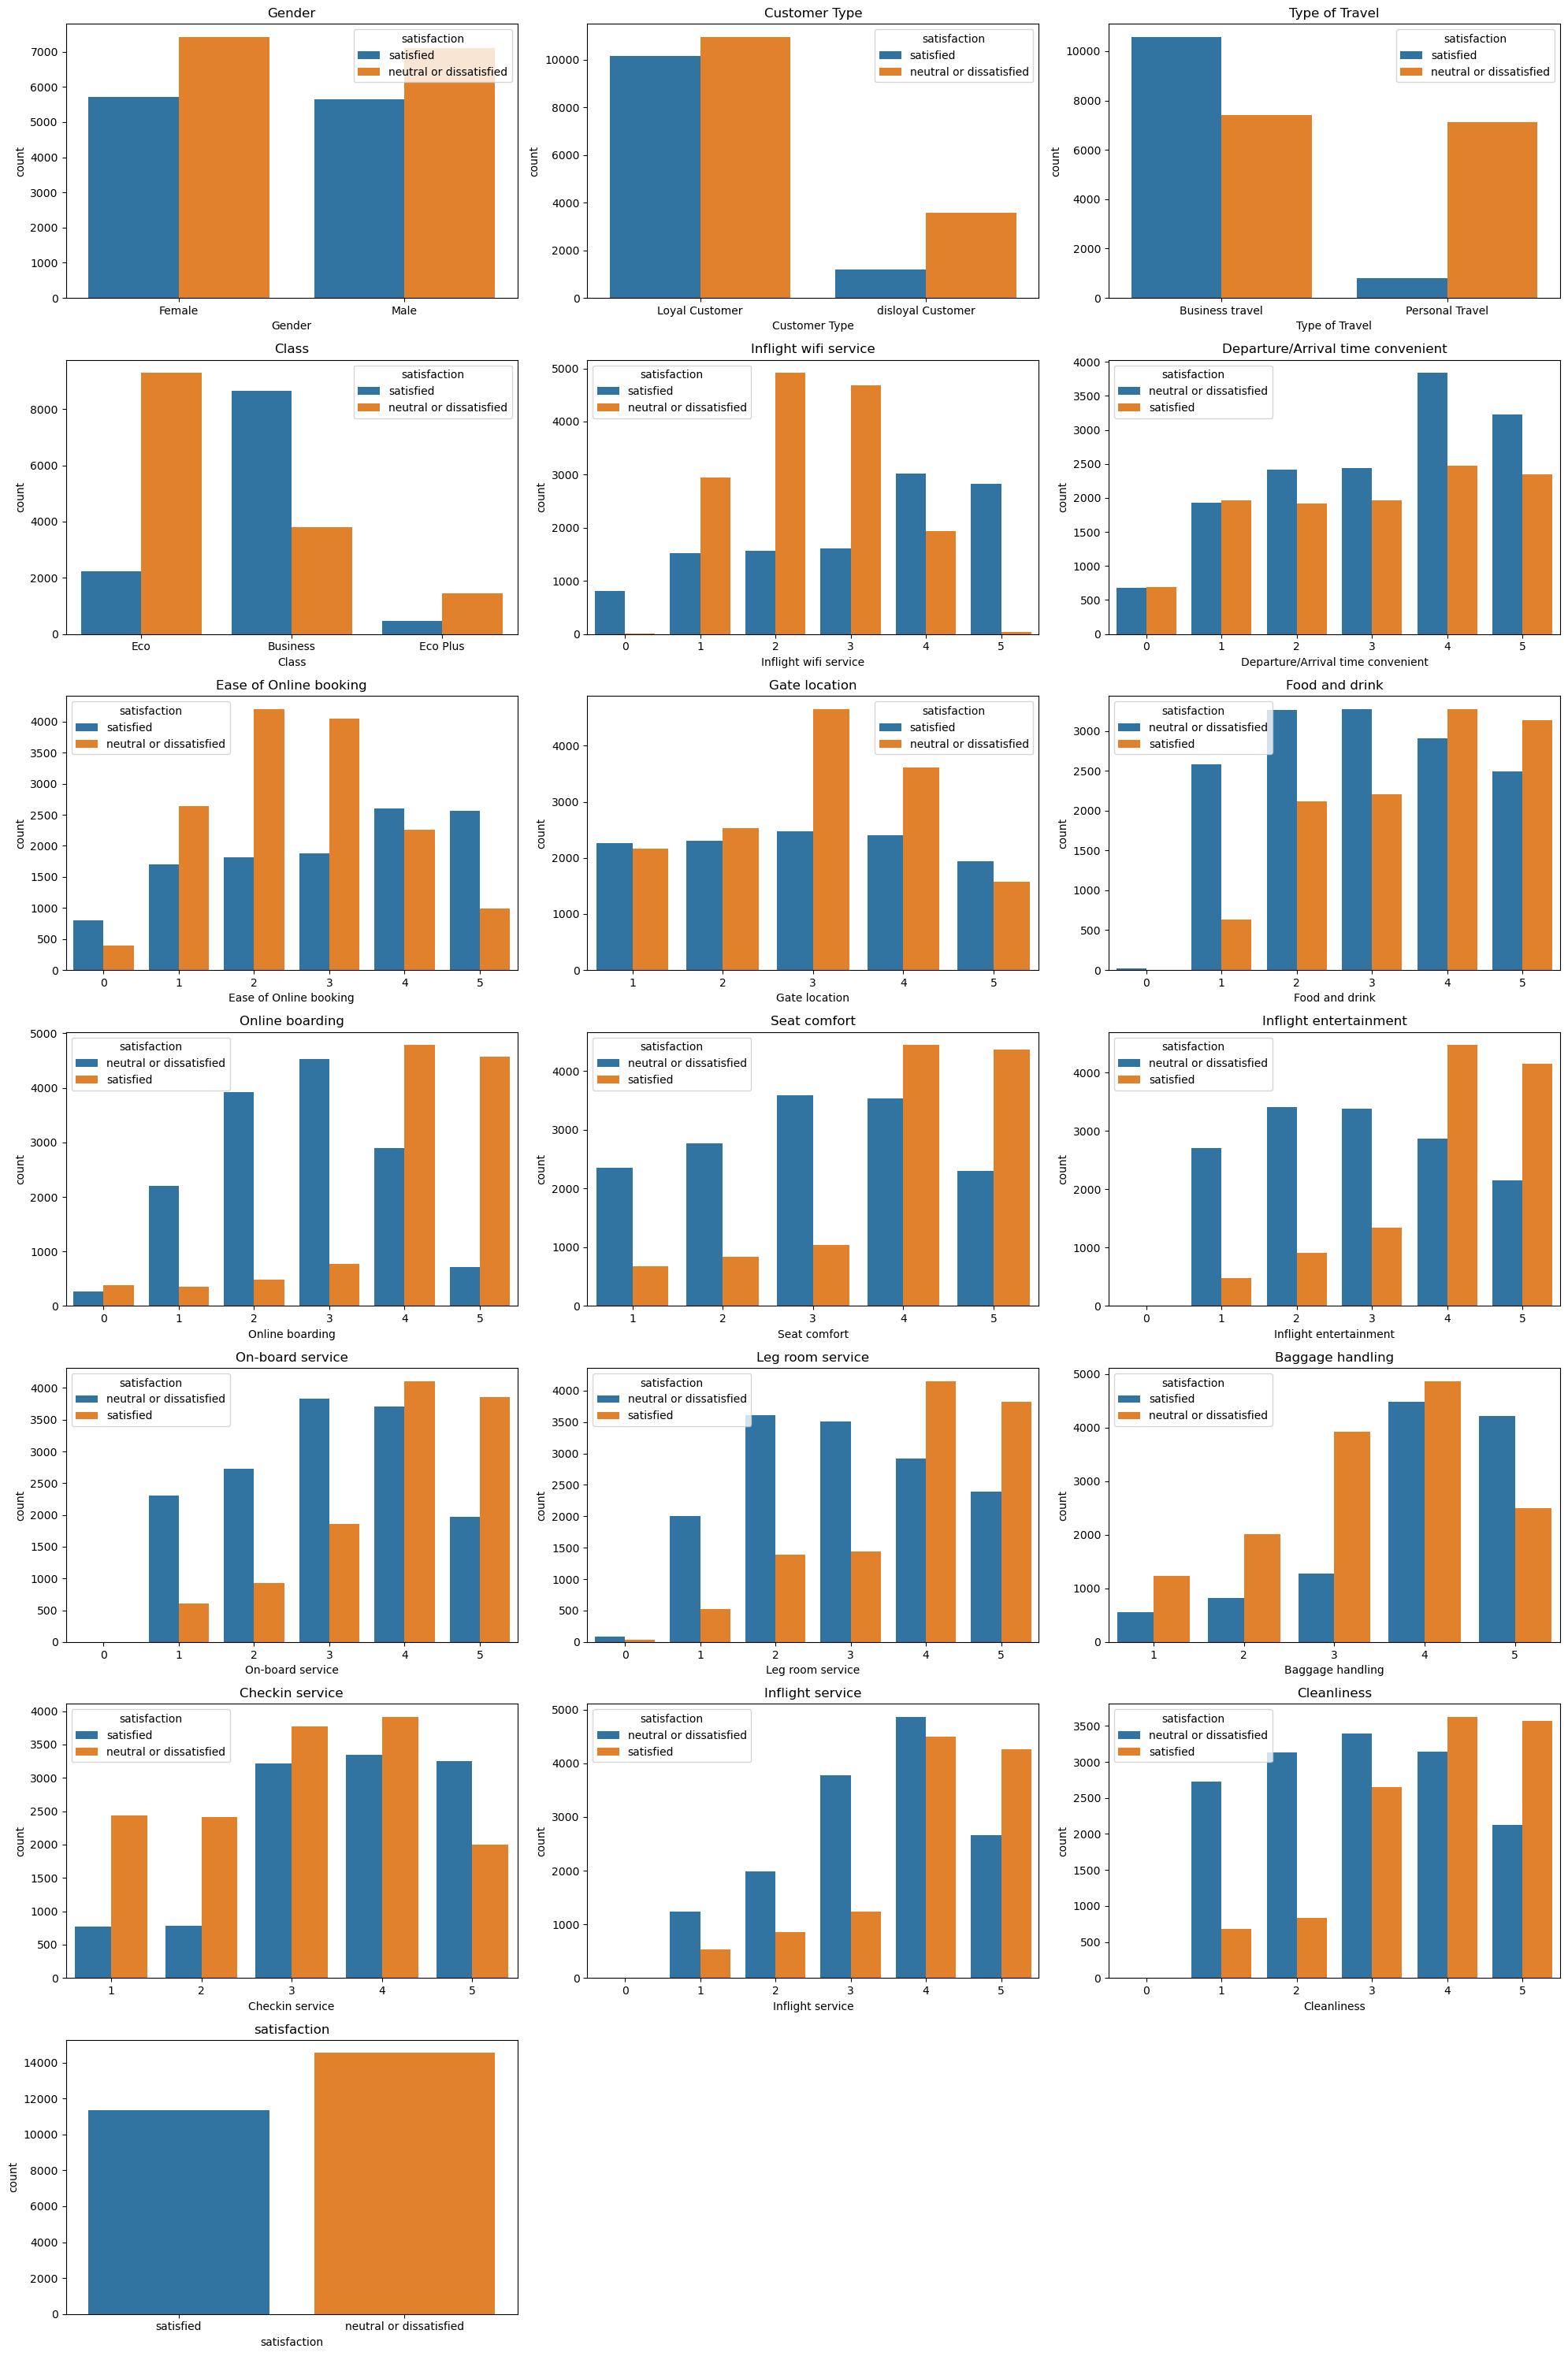

In [149]:
# Cat Columns Distribution
cat_cols = ['Gender', 'Customer Type', 'Type of Travel',
       'Class', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness',
       'satisfaction']

plt.figure(figsize=(20, 30))

for index, col in enumerate(cat_cols, 1):
    plt.subplot(7, 3, index)

    counts = df[col].value_counts(dropna=False)

    sns.countplot(data=df, x=col, hue='satisfaction')

    plt.title(col)

plt.tight_layout()
plt.show()

<Axes: >

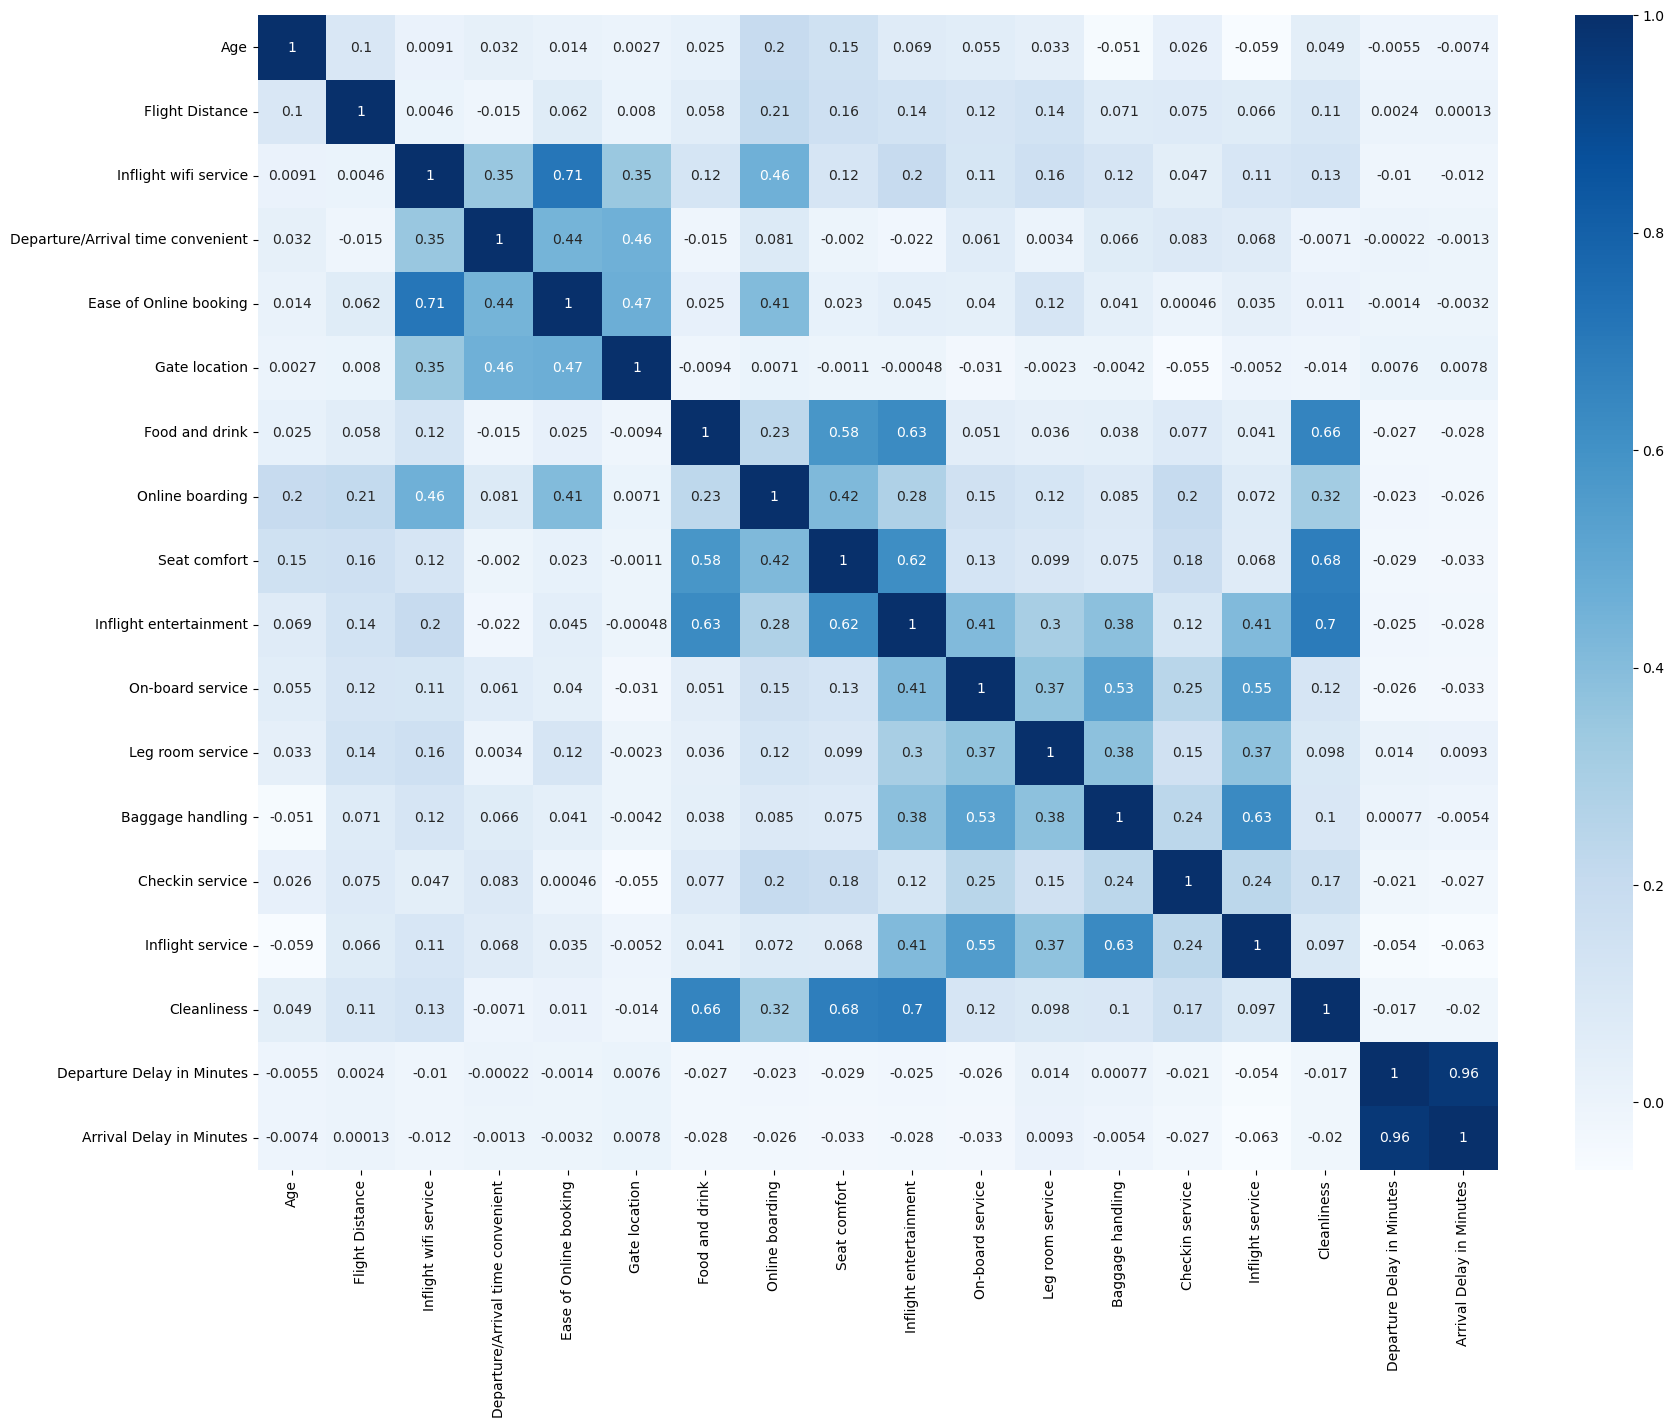

In [150]:
corr = df.select_dtypes('number').corr()

plt.figure(figsize=(20, 15))
sns.heatmap(corr, annot=True, cmap='Blues')

In [151]:
df = df.drop(columns= 'Departure Delay in Minutes')

In [152]:
df.info()

<class 'pandas.DataFrame'>
Index: 25893 entries, 0 to 25975
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             25893 non-null  str    
 1   Customer Type                      25893 non-null  str    
 2   Age                                25893 non-null  int64  
 3   Type of Travel                     25893 non-null  str    
 4   Class                              25893 non-null  str    
 5   Flight Distance                    25893 non-null  int64  
 6   Inflight wifi service              25893 non-null  int64  
 7   Departure/Arrival time convenient  25893 non-null  int64  
 8   Ease of Online booking             25893 non-null  int64  
 9   Gate location                      25893 non-null  int64  
 10  Food and drink                     25893 non-null  int64  
 11  Online boarding                    25893 non-null  int64  
 12  Seat c

# 3. Preprocessing

In [153]:
# Splitting 
X = df.drop(columns=['satisfaction'])
y = df['satisfaction']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

display(X_train.head(5))
display(y_train.head(5))

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Arrival Delay in Minutes
7831,Male,Loyal Customer,35,Business travel,Eco,503,3,5,5,5,3,3,3,3,3,5,4,3,4,3,0.0
14852,Female,Loyal Customer,58,Personal Travel,Eco,1744,2,2,2,4,5,4,4,1,1,2,1,2,1,3,0.0
23193,Female,Loyal Customer,44,Personal Travel,Eco,646,2,4,2,4,3,2,2,2,2,2,2,4,2,5,24.0
14034,Female,Loyal Customer,16,Business travel,Eco,1506,3,3,3,3,3,3,2,3,2,1,3,4,3,3,6.0
15838,Female,Loyal Customer,67,Personal Travel,Business,744,2,3,2,2,5,3,5,3,3,2,2,1,3,4,47.0


7831     neutral or dissatisfied
14852    neutral or dissatisfied
23193    neutral or dissatisfied
14034    neutral or dissatisfied
15838    neutral or dissatisfied
Name: satisfaction, dtype: str

In [154]:
### Encoding

# Columns
onehot_cols = ['Gender', 'Customer Type', 'Type of Travel']
ordinal_cols = ['Class']

# 1. Feature Encoding (One-Hot + Ordinal together)
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'), onehot_cols),
        ('ordinal', OrdinalEncoder(categories=[['Eco', 'Eco Plus', 'Business']]), ordinal_cols),
    ],
    remainder='passthrough',            # don't touch others
    verbose_feature_names_out=False     # Keep columns names with out any prefix
).set_output(transform='pandas')        # return a pandas DataFrame

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded  = preprocessor.transform(X_test)

# 2. Target Encoding
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded  = le.transform(y_test)


# ### Encoding
# # Mapping dictionaries (explicit & readable)
# mappings = {
#     'Gender':         {'Female': 0, 'Male': 1},
#     'Customer Type':  {'disloyal Customer': 0, 'Loyal Customer': 1},
#     'Type of Travel': {'Personal Travel': 0, 'Business travel': 1},
#     'Class':          {'Eco': 0, 'Eco Plus': 1, 'Business': 2},
# }

# for col, mapping in mappings.items():
#     X_train[col] = X_train[col].map(mapping)
#     X_test[col]  = X_test[col].map(mapping)

# # Target mapping
# target_map = {'neutral or dissatisfied': 0, 'satisfied': 1}
# y_train = y_train.map(target_map)
# y_test  = y_test.map(target_map)

# # Quick sanity check to ensure no typos caused NaNs
# assert X_train[list(mappings.keys())].isna().sum().sum() == 0, "Check mapping keys!"

In [155]:
X_train_encoded.head()

,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Arrival Delay in Minutes
7831,1.0,0.0,0.0,0.0,35,503,3,5,5,5,3,3,3,3,3,5,4,3,4,3,0.0
14852,0.0,0.0,1.0,0.0,58,1744,2,2,2,4,5,4,4,1,1,2,1,2,1,3,0.0
23193,0.0,0.0,1.0,0.0,44,646,2,4,2,4,3,2,2,2,2,2,2,4,2,5,24.0
14034,0.0,0.0,0.0,0.0,16,1506,3,3,3,3,3,3,2,3,2,1,3,4,3,3,6.0
15838,0.0,0.0,1.0,2.0,67,744,2,3,2,2,5,3,5,3,3,2,2,1,3,4,47.0


In [157]:
# Scaling
scaler = StandardScaler()

# Columns 
num_cols = ['Age', 'Flight Distance', 'Arrival Delay in Minutes']

# Take a copy
X_train_scaled = X_train_encoded.copy()
X_test_scaled  = X_test_encoded.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train_encoded[num_cols])
X_test_scaled[num_cols]  = scaler.transform(X_test_encoded[num_cols])

display(X_train_scaled.head())
display(X_test_scaled.head())

,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Arrival Delay in Minutes
7831,1.0,0.0,0.0,0.0,-0.308143,-0.691582,3,5,5,5,3,3,3,3,3,5,4,3,4,3,-0.397653
14852,0.0,0.0,1.0,0.0,1.214157,0.551493,2,2,2,4,5,4,4,1,1,2,1,2,1,3,-0.397653
23193,0.0,0.0,1.0,0.0,0.287540,-0.548343,2,4,2,4,3,2,2,2,2,2,2,4,2,5,0.248630
14034,0.0,0.0,0.0,0.0,-1.565695,0.313095,3,3,3,3,3,3,2,3,2,1,3,4,3,3,-0.236082
15838,0.0,0.0,1.0,2.0,1.809840,-0.450179,2,3,2,2,5,3,5,3,3,2,2,1,3,4,0.867985


,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Arrival Delay in Minutes
12343,1.0,0.0,0.0,2.0,0.353727,-1.065206,0,4,0,4,2,4,4,1,1,1,1,5,1,3,-0.397653
8678,1.0,0.0,1.0,0.0,-0.639078,0.427285,4,4,4,1,4,4,3,4,5,5,4,5,4,4,-0.397653
25858,0.0,0.0,0.0,2.0,-0.241956,-0.791749,5,5,5,5,3,4,3,4,4,4,4,5,4,1,-0.397653
17952,0.0,1.0,0.0,2.0,0.155166,-0.392082,2,2,2,1,5,2,5,5,4,4,4,3,5,5,-0.074512
22782,1.0,0.0,0.0,2.0,-0.639078,2.715104,5,5,5,5,3,3,3,3,3,4,5,5,4,3,-0.397653


In [158]:
X_train = X_train_scaled
y_train = y_train_encoded

X_test = X_test_scaled
y_test = y_test_encoded

# 4. Modeling

## Logistic Regression

In [159]:
log_reg = LogisticRegression()

log_reg.fit(X_train, y_train)

log_reg

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

=============== Evaluation =================
Acc: 87.53%

Classification Report:
                         precision    recall  f1-score   support

Neutral or Dissatisfied       0.88      0.90      0.89      2906
              Satisfied       0.87      0.84      0.86      2273

               accuracy                           0.88      5179
              macro avg       0.87      0.87      0.87      5179
           weighted avg       0.88      0.88      0.88      5179



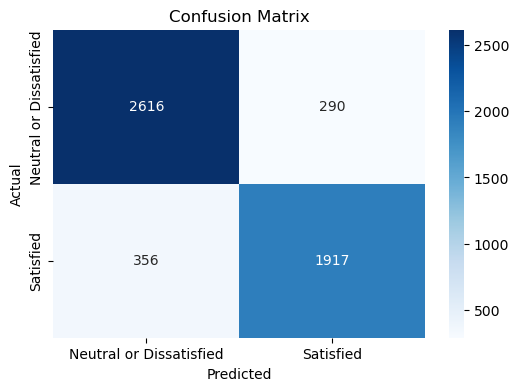

In [167]:
# Eval
class_names = ['Neutral or Dissatisfied', 'Satisfied']
y_pred = log_reg.predict(X_test)

print("=============== Evaluation =================")
print(f"Acc: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    data=conf_matrix,
    cmap='Blues',
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

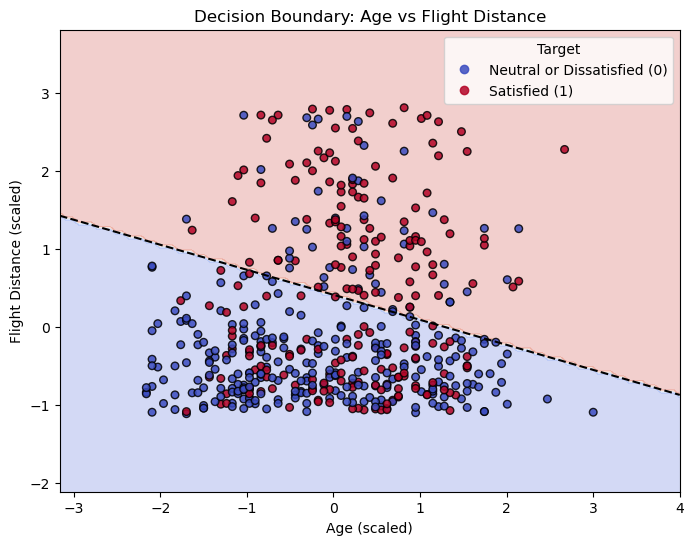

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

# Choose a continues features (To prevent the categorical plotting)
features = ['Age', 'Flight Distance']

model_2d = LogisticRegression()
model_2d.fit(X_train_scaled[features], y_train)

# first 500 samples
X_sample = X_test_scaled[features][:500]
y_sample = y_test[:500]

fig, ax = plt.subplots(figsize=(8, 6))

# Background
DecisionBoundaryDisplay.from_estimator(
    model_2d, X_sample, cmap='coolwarm', alpha=0.25, response_method='predict', ax=ax
)

# Decision Boundary
DecisionBoundaryDisplay.from_estimator(
    model_2d, X_sample, colors='black', linestyles='--', levels=[0],
    response_method='decision_function', plot_method='contour', ax=ax
)

# Classes points (with ti's colors)
scatter = ax.scatter(
    X_sample['Age'], X_sample['Flight Distance'],
    c=y_sample, cmap='coolwarm', edgecolors='k', s=30, alpha=0.85
)

handles, _ = scatter.legend_elements()
ax.legend(handles, ['Neutral or Dissatisfied (0)', 'Satisfied (1)'], title='Target')

ax.set_title('Decision Boundary: Age vs Flight Distance')
ax.set_xlabel('Age (scaled)')
ax.set_ylabel('Flight Distance (scaled)')
plt.show()

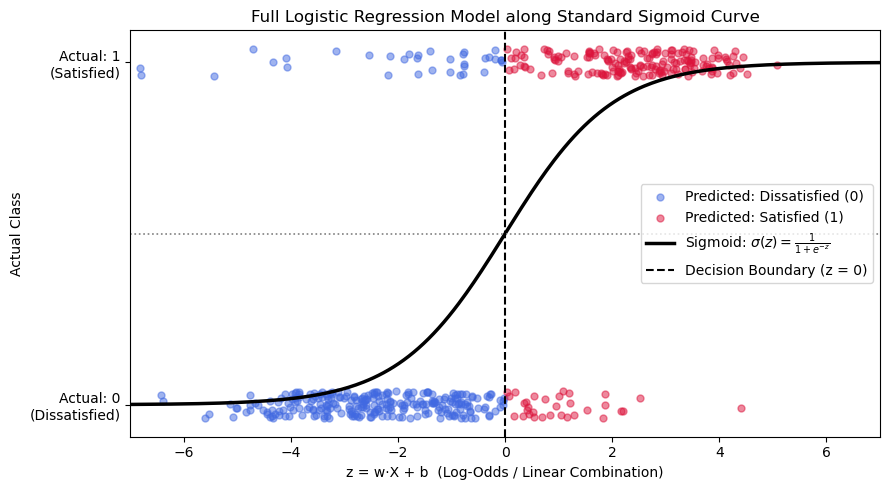

In [175]:
# first 500 as a sample of test data
X_sample = X_test[:500]
y_actual = np.asarray(y_test)[:500]

# z = w*x + b and the prediction for each point
z_sample = log_reg.decision_function(X_sample)
y_pred_sample = log_reg.predict(X_sample)

# Decision Boundary
z_line = np.linspace(-7, 7, 300)
sigmoid_curve = 1 / (1 + np.exp(-z_line))

# Small Jitter for points not lie on each other
np.random.seed(42)
y_jitter = y_actual + np.random.uniform(-0.04, 0.04, size=len(y_actual))

plt.figure(figsize=(9, 5))

# Points with it's axis and color
plt.scatter(z_sample[y_pred_sample == 0], y_jitter[y_pred_sample == 0],
            color='royalblue', alpha=0.5, s=25, label='Predicted: Dissatisfied (0)')
plt.scatter(z_sample[y_pred_sample == 1], y_jitter[y_pred_sample == 1],
            color='crimson', alpha=0.5, s=25, label='Predicted: Satisfied (1)')

# log_reg curve
plt.plot(z_line, sigmoid_curve, color='black', linewidth=2.5, label=r'Sigmoid: $\sigma(z) = \frac{1}{1 + e^{-z}}$')

# Intersected lines
plt.axhline(0.5, color='gray', linestyle=':', linewidth=1.2)
plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Decision Boundary (z = 0)')

plt.xlim(-7, 7)
plt.yticks([0, 1], ['Actual: 0\n(Dissatisfied)', 'Actual: 1\n(Satisfied)'])
plt.xlabel('z = w·X + b  (Log-Odds / Linear Combination)')
plt.ylabel('Actual Class')
plt.title('Full Logistic Regression Model along Standard Sigmoid Curve')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

$$z = w^T x + b$$

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

## KNN

### K-Nearest Neighbors Formulation

**1. Euclidean Distance Metric ($L_2$ Norm):**
The standard straight-line distance, known in linear algebra as the $L_2$ norm, between a query sample $x$ and a training sample $x_i$ across $p$ continuous features:
$$d_{\text{Euclidean}}(x, x_i) = \|x - x_i\|_2 = \sqrt{\sum_{j=1}^{p} (x_j - x_{ij})^2}$$

**2. Manhattan Distance Metric ($L_1$ Norm):**
The city-block or taxicab distance, known in linear algebra as the $L_1$ norm, measuring the sum of absolute coordinate differences across $p$ features (often preferred in higher dimensions or with ordinal features, as configured in the model below):
$$d_{\text{Manhattan}}(x, x_i) = \|x - x_i\|_1 = \sum_{j=1}^{p} |x_j - x_{ij}|$$

**3. Neighbor Decision Rule:**
Given the set of $K$ nearest neighbors $N_K(x)$ to query point $x$, the predicted class $\hat{y}$ is determined by majority vote:
$$\hat{y} = \arg\max_{c} \sum_{i \in N_K(x)} I(y_i = c)$$

*(Distance-Weighted Decision Rule, as configured in this session via `weights='distance'`)*:
$$\hat{y} = \arg\max_{c} \sum_{i \in N_K(x)} w_i \cdot I(y_i = c), \quad \text{where } w_i = \frac{1}{d(x, x_i)}$$


In [176]:
# KNN
knn = KNeighborsClassifier(
    n_neighbors=7,      # Note: Odd number avoids tie votes in binary classification
    weights='distance', # Closer neighbors have more influence than farther ones
    metric='manhattan', # Often outperforms Euclidean in ~20D with ordinal/binary features
    n_jobs=-1           # Uses all CPU cores to speed up prediction
)

knn.fit(X_train_scaled, y_train)
knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'


=============== Evaluation =================
Acc: 93.20%

Classification Report:
                         precision    recall  f1-score   support

Neutral or Dissatisfied       0.93      0.95      0.94      2906
              Satisfied       0.93      0.91      0.92      2273

               accuracy                           0.93      5179
              macro avg       0.93      0.93      0.93      5179
           weighted avg       0.93      0.93      0.93      5179



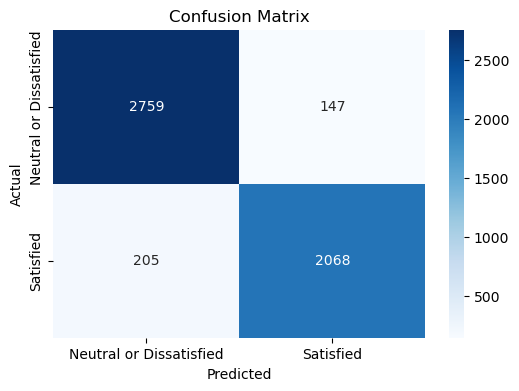

In [177]:
# Eval
class_names = ['Neutral or Dissatisfied', 'Satisfied']
y_pred = knn.predict(X_test)

print("=============== Evaluation =================")
print(f"Acc: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    data=conf_matrix,
    cmap='Blues',
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Evaluation

1. **Accuracy:**
   Measures the proportion of correctly classified instances out of the total number of predictions made across all classes.
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

2. **Precision:**
   Measures the proportion of true positive predictions among all instances predicted as positive by the model.
   $$\text{Precision} = \frac{TP}{TP + FP}$$

3. **Recall (Sensitivity):**
   Measures the proportion of actual positive instances that were correctly identified by the model.
   $$\text{Recall} = \frac{TP}{TP + FN}$$

4. **F1 Score:**
   The harmonic mean of precision and recall, providing a single balanced performance measure for classification under class imbalance.
   $$\text{F1 Score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

### Additional

Total Variance Kept in 2D: 39.1%
2D PCA KNN Accuracy: 78.51%


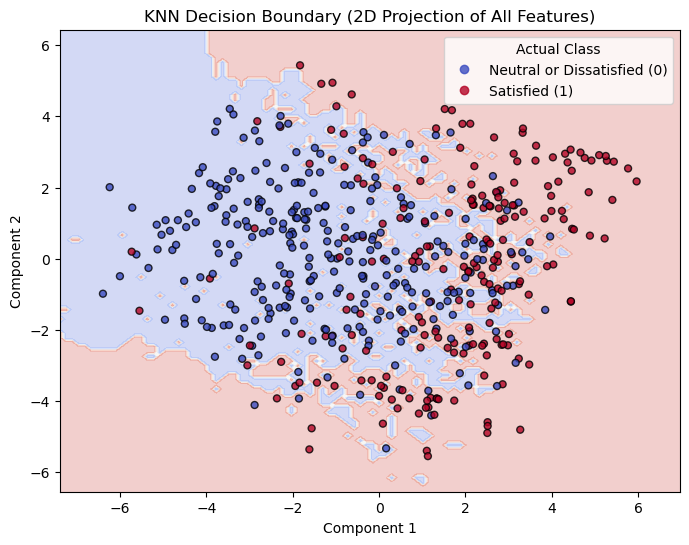

In [181]:
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Data Compression From 21-D to 2D (could be visualized)
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca  = pca.transform(X_test)

print(f"Total Variance Kept in 2D: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

# 2. Train KNN after compression on 2D data
knn_pca = KNeighborsClassifier(n_neighbors=7, weights='distance', metric='manhattan')
knn_pca.fit(X_train_pca, y_train)
print(f"2D PCA KNN Accuracy: {knn_pca.score(X_test_pca, y_test) * 100:.2f}%")

# 3. Plot on 500 samples
X_sample = X_test_pca[:500]
y_sample = np.asarray(y_test)[:500]

fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    knn_pca, X_sample, cmap='coolwarm', alpha=0.25, response_method='predict', ax=ax
)

scatter = ax.scatter(
    X_sample[:, 0], X_sample[:, 1],
    c=y_sample, cmap='coolwarm', edgecolors='k', s=25, alpha=0.8
)

handles, _ = scatter.legend_elements()
ax.legend(handles, ['Neutral or Dissatisfied (0)', 'Satisfied (1)'], title='Actual Class')
ax.set_title('KNN Decision Boundary (2D Projection of All Features)')
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
plt.show()